## ДЗ №1. Метрики и простейшие алгоритмы рекомендаций

In [1]:
import os, tempfile, urllib.request, zipfile
from pathlib import Path
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tqdm.auto import tqdm
from typing import List, Optional
from scipy import sparse as sps
np.random.seed(777)
%matplotlib inline
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)

C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## О задании

В этой работе мы посмотрим на то, как работают самые простые модели для рекомендаций. Как правило, они не требуют построения специальных моделей, но даже так оказываются полезны в качестве бейзлайна. Попробуем сделать предсказания с помощью EASE. Это тоже довольно простой подход, но не стоит забывать, что сложные модели могут оказаться не лучшим выбором в условиях большого количества данных. Посчитаем метрики, построим графики и подумаем, насколько хорошо эти модели вообще решают поставленную задачу.

Мы будем работать с датасетом по рекомендации фильмов от Kion MTS, который был дан для соревнования. Сперва нужно его предобработать, эта часть повторяет то, что было на семинаре. 

Датасет необходимо скачать: https://ods.ai/competitions/competition-recsys-21/data

Оттуда нужны файлы `interactions.csv` и `items.csv`

Каждое задание весит **1 балл**, если выполнено полностью и без ошибок, **0 баллов** ставится при наличии хотя бы 1 ошибки. Максимальная оценка - **10 баллов**. Шаблоны функций и классов можно менять по своему усмотрению.

In [2]:
# Полный официальный архив: https://github.com/irsafilo/KION_DATASET
cache = Path(tempfile.gettempdir()) / 'kion_recsys_dataset'
cache.mkdir(exist_ok=True)
url = 'https://raw.githubusercontent.com/irsafilo/KION_DATASET/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip'
archive_path = cache / 'data_original.zip'
if not archive_path.exists():
    urllib.request.urlretrieve(url, archive_path)
with zipfile.ZipFile(archive_path) as archive:
    print('Архив:', archive.namelist())
    interaction_path = next(x for x in archive.namelist() if x.endswith('/interactions.csv'))
    items_path = next(x for x in archive.namelist() if x.endswith('/items.csv'))
    with archive.open(interaction_path) as f:
        df = pd.read_csv(f, usecols=['user_id', 'item_id', 'last_watch_dt'])
    with archive.open(items_path) as f:
        items = pd.read_csv(f, usecols=['item_id', 'title'])
print('Взаимодействий:', len(df))
assert len(df) == 5_476_251
df.head()

Архив: ['data_original/', 'data_original/interactions.csv', '__MACOSX/data_original/._interactions.csv', 'data_original/users.csv', '__MACOSX/data_original/._users.csv', 'data_original/items.csv', '__MACOSX/data_original/._items.csv']


Взаимодействий: 5476251


,user_id,item_id,last_watch_dt
0,176549,9506,2021-05-11
1,699317,1659,2021-05-29
2,656683,7107,2021-05-09
3,864613,7638,2021-07-05
4,964868,9506,2021-04-30


In [3]:
dates = pd.to_datetime(df['last_watch_dt'], errors='coerce')
print('Строк с некорректной датой:', dates.isna().sum())
df = df.loc[dates.notna()].copy()
dates = dates.dropna()
df['last_watch_dt'] = (dates - dates.min()).dt.days.astype('int16')
print('Период:', dates.min().date(), '—', dates.max().date())
df.sample(5, random_state=777)

Строк с некорректной датой: 0


Период: 2021-03-13 — 2021-08-22


,user_id,item_id,last_watch_dt
733478,403171,334,102
2464785,563681,488,92
797587,590787,7571,102
234877,82356,14883,45
3893514,572165,7745,142


Сделаем разбиение по времени

<Axes: >

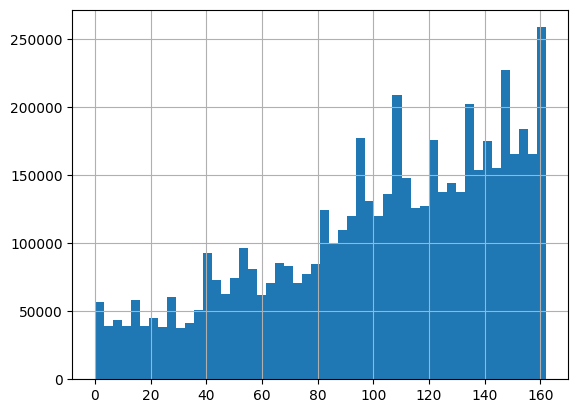

In [4]:
df.last_watch_dt.hist(bins=50)

In [5]:
train_df = df.loc[(df.last_watch_dt < 160-7)].copy()
test_df = df.loc[(df.last_watch_dt >= 160-7)].copy()

train_users = train_df.user_id.unique()
test_users = test_df.user_id.unique()

all_included = np.intersect1d(train_users, test_users)

print('число людей и там и там: ', all_included.shape[0])
print('число людей всего:', train_users.shape[0])

число людей и там и там:  134670
число людей всего: 880449


In [6]:
len(set(test_users) - set(train_users)) / len(test_users)

0.37768022181146027

И переведём всё к соединённому датасету:

In [7]:
n_users = 10000

np.random.seed(777)
all_included = np.random.choice(all_included, size=n_users, replace=False)

train_df = train_df.loc[train_df.user_id.isin(all_included)].copy()
test_df = test_df.loc[test_df.user_id.isin(all_included)].copy()

assert train_df.last_watch_dt.max() < test_df.last_watch_dt.min()
assert train_df.user_id.nunique() == n_users
assert test_df.user_id.nunique() == n_users

In [8]:
train_df.head()

,user_id,item_id,last_watch_dt
32,141674,3813,60
71,785328,13165,13
131,470881,11800,100
183,339681,13865,92
247,284039,9728,122


In [9]:
train_grouped = train_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                 x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
train_grouped.rename({0:'train_interactions'}, axis=1, inplace=True)

test_grouped = test_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                         x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
test_grouped.rename({0:'test_interactions'}, axis=1, inplace=True)

train_grouped.head()

C:\Users\Иван\AppData\Local\Temp\ipykernel_34396\1105526701.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_grouped = train_df.groupby('user_id').apply(


C:\Users\Иван\AppData\Local\Temp\ipykernel_34396\1105526701.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_grouped = test_df.groupby('user_id').apply(


,user_id,train_interactions
0,382,"[(1112, 89), (565, 129), (10605, 131), (5411, ..."
1,446,"[(13865, 105)]"
2,515,"[(3734, 114), (9728, 114), (4457, 115), (13865..."
3,545,"[(10440, 92), (5803, 92), (6106, 103), (6455, ..."
4,587,"[(4151, 64), (1400, 64), (4880, 69), (5658, 70..."


In [10]:
joined = train_grouped.merge(test_grouped)
joined.head()

,user_id,train_interactions,test_interactions
0,382,"[(1112, 89), (565, 129), (10605, 131), (5411, ...","[(11047, 153)]"
1,446,"[(13865, 105)]","[(12202, 160), (230, 160)]"
2,515,"[(3734, 114), (9728, 114), (4457, 115), (13865...","[(512, 158), (6330, 158), (9811, 159), (14488,..."
3,545,"[(10440, 92), (5803, 92), (6106, 103), (6455, ...","[(6638, 158), (5693, 161)]"
4,587,"[(4151, 64), (1400, 64), (4880, 69), (5658, 70...","[(11118, 153), (6192, 154)]"


In [11]:
class Random:
    def fit(self, df, col='train_interactions'):
        self.items = np.array(sorted({item for seq in df[col] for item, _ in seq}))
        return self
    def predict(self, df, topn=10):
        rng = np.random.default_rng(777)
        return [rng.choice(self.items, size=min(topn, len(self.items)), replace=False) for _ in range(len(df))]
random = Random().fit(joined)
joined['random_recs'] = random.predict(joined, topn=10)
joined.head()

,user_id,train_interactions,test_interactions,random_recs
0,382,"[(1112, 89), (565, 129), (10605, 131), (5411, ...","[(11047, 153)]","[7498, 14901, 1582, 10162, 9978, 15885, 5232, ..."
1,446,"[(13865, 105)]","[(12202, 160), (230, 160)]","[2782, 10494, 15572, 11310, 956, 12598, 8815, ..."
2,515,"[(3734, 114), (9728, 114), (4457, 115), (13865...","[(512, 158), (6330, 158), (9811, 159), (14488,...","[4127, 3609, 1682, 4366, 565, 13655, 7250, 811..."
3,545,"[(10440, 92), (5803, 92), (6106, 103), (6455, ...","[(6638, 158), (5693, 161)]","[2190, 9742, 16224, 2972, 752, 14685, 1240, 12..."
4,587,"[(4151, 64), (1400, 64), (4880, 69), (5658, 70...","[(11118, 153), (6192, 154)]","[2591, 1821, 14271, 12628, 1819, 3761, 2433, 1..."


**Задание №1. Метрики и бейзлайны**

Добавьте реализацию метрик AP, RR, HR, их усреднённые версии по $U$ мы посчитаем ниже, если следовать коду с семинара, поэтому формулы немного отличаются. За имплементацию с циклами балл будет снижаться, векторизуйте! ( ͡° ͜ʖ ͡°)

$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$
p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)
$$
$$
RR@k = \dfrac{1}{\text{rank}_i@k}
$$
$$
HR@k = [\exists \ y_i = 1 \ \text{among k preds}]
$$


*   $n_u$ - число айтемов, с которыми взаимодействовал юзер $u$
*   $y_i$ - релевантно ли $i$-ое предсказание, $y_i \in \{0,1\}$
* $\text{rank}_i@k$ - позиция первого релеваннтого айтема среди первых $k$ предсказаний
* HR@k - среди первых $k$ предсказаний есть хотя бы одно релевантное

Считайте, что если `topn` не задано, то берётся всегда $n_u$. 

In [12]:
def _hits(gt_items, predictions, topn=None):
    gt = np.unique(gt_items)
    k = len(gt) if topn is None else max(0, int(topn))
    pred = np.asarray(predictions)[:k]
    # Повтор одной рекомендации не может принести второе попадание.
    unique = ~pd.Index(pred).duplicated()
    return np.isin(pred, gt) & unique, min(k, len(gt))

def ap_metric(gt_items: List[int], predictions: List[int], topn: Optional[int]=None):
    ### your code here
    hits, denom = _hits(gt_items, predictions, topn)
    return float(np.sum(hits * np.cumsum(hits) / np.arange(1, len(hits) + 1)) / denom) if denom else 0.0

def rr_metric(gt_items: List[int], predictions: List[int], topn: Optional[int]=None):
    ### your code here
    hits, _ = _hits(gt_items, predictions, topn)
    return float(1 / (np.argmax(hits) + 1)) if hits.any() else 0.0

def hr_metric(gt_items: List[int], predictions: List[int], topn: Optional[int]=None):
    ### your code here
    hits, _ = _hits(gt_items, predictions, topn)
    return float(hits.any())

Вместо отсутствующего в репозитории `metric_tests.py` ниже приведены самостоятельные проверки, в том числе пустых и повторяющихся предсказаний.

In [13]:
assert np.isclose(ap_metric([1, 2], [2, 3, 1], 3), (1 + 2/3) / 2)
assert rr_metric([1], [3, 1], 2) == .5
assert hr_metric([1], [2, 3], 2) == 0
assert ap_metric([1], [1, 1], 2) == 1
assert ap_metric([], [1], 10) == rr_metric([], [1], 10) == hr_metric([], [1], 10) == 0
assert hr_metric([1, 2], [3, 1, 2]) == 1
print('Проверки метрик пройдены')

Проверки метрик пройдены


В следующей ячейке код, который считает и усредняет метрики по юзерам. Он взят с семинара, при желании можно его тоже модифицировать, например, векторизовать. 

In [14]:
def evaluate_recommender(df, model_preds, gt_col='test_interactions', topn=None):
    sums = np.zeros(3)
    for gt_seq, pred in zip(df[gt_col], df[model_preds]):
        gt = {x[0] for x in gt_seq}
        k = len(gt) if topn is None else max(0, int(topn))
        seen = set()
        hits = []
        for item in pred[:k]:
            hits.append(item in gt and item not in seen)
            seen.add(item)
        hits = np.asarray(hits, dtype=bool)
        if hits.any():
            positions = np.flatnonzero(hits) + 1
            sums += [np.sum(np.arange(1, len(positions)+1) / positions) / min(k, len(gt)), 1 / positions[0], 1]
    return dict(zip(['map', 'mrr', 'hr'], sums / len(df)))

Если вы всё сделали правильно, рандомные предсказания должны дать хоть какое-то качество, но не очень большое.

In [15]:
evaluate_recommender(joined, model_preds='random_recs')

{'map': 0.00031241716335194585, 'mrr': 0.0011534523809523809, 'hr': 0.0027}

In [16]:
class TopPopular:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        counts = {}
        for _, row in df.iterrows():
            for item, _ in row[col]:
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1

        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:

        assert self.trained
        return [self.recommenations[:topn]]*len(df)


toppop = TopPopular()
toppop.fit(joined)

joined['toppopular_recs'] = toppop.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,382,"[(1112, 89), (565, 129), (10605, 131), (5411, ...","[(11047, 153)]","[7498, 14901, 1582, 10162, 9978, 15885, 5232, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
1,446,"[(13865, 105)]","[(12202, 160), (230, 160)]","[2782, 10494, 15572, 11310, 956, 12598, 8815, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
2,515,"[(3734, 114), (9728, 114), (4457, 115), (13865...","[(512, 158), (6330, 158), (9811, 159), (14488,...","[4127, 3609, 1682, 4366, 565, 13655, 7250, 811...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
3,545,"[(10440, 92), (5803, 92), (6106, 103), (6455, ...","[(6638, 158), (5693, 161)]","[2190, 9742, 16224, 2972, 752, 14685, 1240, 12...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
4,587,"[(4151, 64), (1400, 64), (4880, 69), (5658, 70...","[(11118, 153), (6192, 154)]","[2591, 1821, 14271, 12628, 1819, 3761, 2433, 1...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."


Самые популярные предсказания должны показать более высокое качество.

In [17]:
evaluate_recommender(joined, model_preds='toppopular_recs')

{'map': 0.03729725410564009, 'mrr': 0.08720972222222262, 'hr': 0.1465}

**Задание №2. Рекомендации в окне**

Здесь необходимо переделать метод рекомендации по популярности так, что популярность считается только за какое-то более свежее временное окно. Под окном подразумевается какой-то временной промежуток, например, ближайший месяц. Соответственно, всё что за его пределами, не учитывается.

In [18]:
class TopPopularWeighted(TopPopular):
    def __init__(self, min_window=2):
        super().__init__()
        self.min_window = min_window
    def fit(self, df, col='train_interactions'):
        # your code here
        pairs = [(item, day) for seq in df[col] for item, day in seq]
        end = max(day for _, day in pairs)
        counts = pd.Series([item for item, day in pairs if day > end - self.min_window]).value_counts()
        self.recommenations = counts.index.tolist()
        self.trained = True
        return self

Теперь постройте графики зависимости значений трёх метрик (AP@k, RR@k, HR@k) от размера окна. 

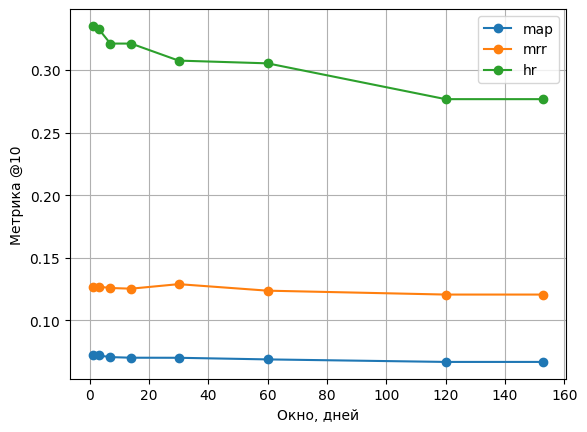

,map,mrr,hr
1,0.072507,0.127112,0.3353
3,0.072050,0.127022,0.3330
7,0.070719,0.125926,0.3212
14,0.070231,0.125391,0.3212
30,0.070177,0.129004,0.3076
60,0.068885,0.123791,0.3054
120,0.066869,0.120683,0.2768
153,0.066869,0.120683,0.2768


In [19]:
# your code here
windows = [1, 3, 7, 14, 30, 60, 120, 153]
window_results = []
for window in windows:
    model = TopPopularWeighted(window).fit(joined)
    joined['window_recs'] = model.predict(joined, topn=10)
    window_results.append(evaluate_recommender(joined, 'window_recs', topn=10))
window_table = pd.DataFrame(window_results, index=windows)
window_table.plot(marker='o', xlabel='Окно, дней', ylabel='Метрика @10', grid=True)
plt.show()
window_table

Лучший MAP@10 среди проверенных окон получился при окне в 1 день: 0,0725 против 0,0669 для всей истории. Окно 30 дней дало максимальный MRR@10 (0,1290). Свежесть может лучше отражать текущий спрос, но это наблюдение не доказывает причину.

**Задание №3. Метрики и k.**

Постройте зависимость значений MAP@K, MRR@K, HR@K для метода рекомендации по популярности. Возьмите какие-нибудь k, например, от 1 до 100, переберите значения и покажите на линейном графике. 

In [20]:
joined['toppopular_recs'] = toppop.predict(joined, topn=100)

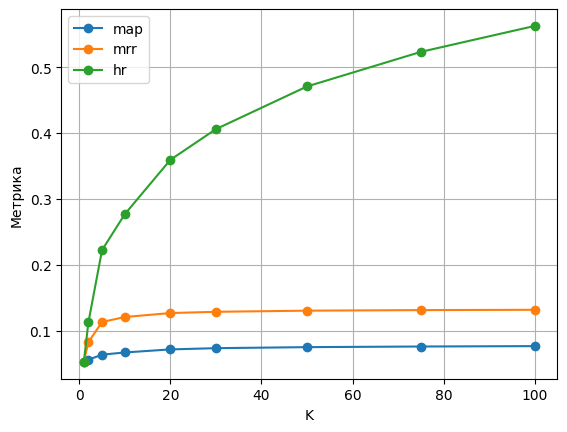

,map,mrr,hr
1,0.052500,0.052500,0.0525
2,0.055875,0.082450,0.1124
5,0.063494,0.113083,0.2223
10,0.066869,0.120683,0.2768
20,0.071490,0.126674,0.3593
30,0.073380,0.128599,0.4059
50,0.074938,0.130316,0.4707
75,0.075898,0.131169,0.5232
100,0.076485,0.131628,0.5626


In [21]:
# your code here
ks = [1, 2, 5, 10, 20, 30, 50, 75, 100]
pop_curve = pd.DataFrame([evaluate_recommender(joined, 'toppopular_recs', topn=k) for k in ks], index=ks)
pop_curve.plot(marker='o', xlabel='K', ylabel='Метрика', grid=True)
plt.show()
pop_curve

3.1 HR и RR не убывают при увеличении K: добавление позиций не отменяет найденное попадание и не меняет позицию первого. AP может снизиться: знаменатель min(K, число релевантных) растёт, даже если новых попаданий нет.

3.2 HR показывает долю пользователей, которые встретят хотя бы один интересный объект, RR учитывает, как рано он встретится. AP учитывает позиции всех найденных релевантных объектов и штрафует за пропущенные. Чем дальше пользователь листает, тем больше шансов встретить подходящий объект.

3.3 Вид кривых зависит от числа релевантных объектов и их рангов. HR и RR по определению не убывают, MAP не обязан быть монотонным. Здесь релевантными считаются просмотры в последнюю неделю, а не непосредственно измеренное удовольствие пользователя.

**Задание №4. Интерпретация рейтингов**

Возьмите названия фильмов/сериалов из `items.csv`, выделите 5 различных сценариев изменения популярности у фильмов, аргументируйте (например, графиком или статистикой) и проинтерпретируейте их (почему популярность для этого фильма меняется так). Обратите внимание, что надо найти именно разные паттерны изменения вероятностей. 

In [22]:
items.head()

,item_id,title
0,10711,Поговори с ней
1,2508,Голые перцы
2,10716,Тактическая сила
3,7868,45 лет
4,16268,Все решает мгновение


Пример:

1917


<Axes: >

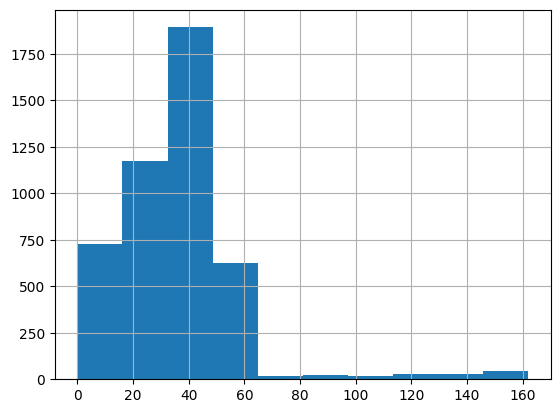

In [23]:
popular_items = df.item_id.value_counts()[:300].index.tolist()
sampled_id = np.random.choice(popular_items)

# это для примера, хотя выцеплять случаи по одному может быть не лучшей идеей
sampled_id = 3402

interactions = df.loc[df.item_id==sampled_id].copy()
name = items.loc[items.item_id==sampled_id].title.values[0]
print(name)
interactions.last_watch_dt.hist()

Фильм 1917 какое-то время набирал популярность, потом видим резкое падение (кстати, с какой даты?). Возможно, это связано с ограничением доступности этого фильма для части пользователей, периодом проката фильма / рекламной кампании или другой причиной. 

Добавьте 5 своих примеров ниже. Опишите, как вы их искали. 

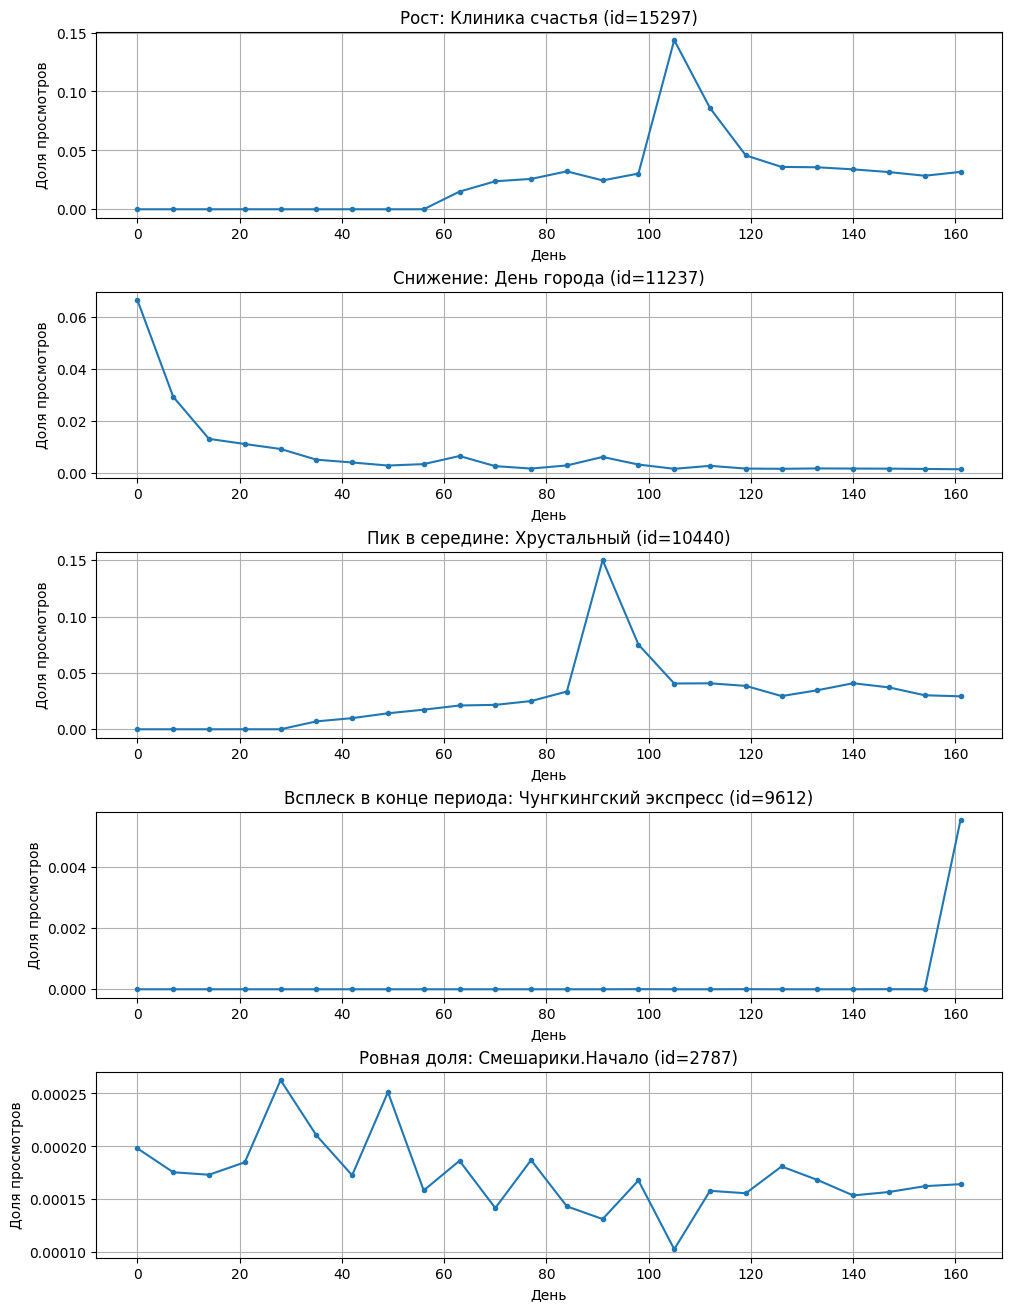

Выбраны фильмы с не менее 500 взаимодействиями по показателям формы доли просмотров, причины изменений без внешних данных неизвестны.


,Название,Сценарий,Начало,Середина,Конец,Неделя пика
0,Клиника счастья,Рост,0.000000,3.687606e-02,0.041105,15
1,День города,Снижение,0.017720,3.571172e-03,0.001818,0
2,Хрустальный,Пик в середине,0.003877,4.803560e-02,0.035075,13
3,Чунгкингский экспресс,Всплеск в конце периода,0.000000,4.280851e-07,0.000694,23
4,Смешарики.Начало,Ровная доля,0.000204,1.523418e-04,0.000163,4


Клиника счастья — рост: доли в начале, середине и конце 0.0000%, 3.6876%, 4.1105%, пик на неделе 15. Это наблюдаемая форма, возможны изменения доступности или интереса, но данные не устанавливают причину.
День города — снижение: доли в начале, середине и конце 1.7720%, 0.3571%, 0.1818%, пик на неделе 0. Это наблюдаемая форма, возможны изменения доступности или интереса, но данные не устанавливают причину.
Хрустальный — пик в середине: доли в начале, середине и конце 0.3877%, 4.8036%, 3.5075%, пик на неделе 13. Это наблюдаемая форма, возможны изменения доступности или интереса, но данные не устанавливают причину.
Чунгкингский экспресс — всплеск в конце периода: доли в начале, середине и конце 0.0000%, 0.0000%, 0.0694%, пик на неделе 23. Это наблюдаемая форма, возможны изменения доступности или интереса, но данные не устанавливают причину.
Смешарики.Начало — ровная доля: доли в начале, середине и конце 0.0204%, 0.0152%, 0.0163%, пик на неделе 4. Это наблюдаемая форма, возможны изменения 

In [24]:
# your code here
# Нормируем число взаимодействий по общему числу просмотров в каждом недельном интервале.
daily = df.assign(week=df.last_watch_dt // 7)
total = daily.groupby('week').size()
counts = daily.groupby(['item_id', 'week']).size().unstack(fill_value=0).reindex(columns=total.index, fill_value=0)
shares = counts.div(total, axis=1)
eligible = shares.loc[counts.sum(axis=1) >= 500]
a = eligible.to_numpy()
thirds = np.array_split(np.arange(a.shape[1]), 3)
early, middle, late = [a[:, idx].mean(axis=1) for idx in thirds]
# Отбираем разные формы по разнице средних долей и концентрации пика.
criteria = [late-early, early-late, middle-(early+late)/2,
            a.max(axis=1)/(a.mean(axis=1)+1e-12), -np.std(a, axis=1)/(a.mean(axis=1)+1e-12)]
labels = ['Рост', 'Снижение', 'Пик в середине', 'Всплеск в конце периода', 'Ровная доля']
chosen=[]
for score in criteria:
    for pos in np.argsort(score)[::-1]:
        item = eligible.index[pos]
        if item not in chosen and item in set(items.item_id):
            chosen.append(item)
            break
fig, axes = plt.subplots(5, 1, figsize=(10, 13), constrained_layout=True)
for ax, item, label in zip(axes, chosen, labels):
    title = items.set_index('item_id').loc[item, 'title']
    ax.plot(total.index * 7, shares.loc[item], marker='.', label=str(title))
    ax.set(title=f'{label}: {title} (id={item})', xlabel='День', ylabel='Доля просмотров')
    ax.grid()
plt.show()
print('Выбраны фильмы с не менее 500 взаимодействиями по показателям формы доли просмотров, причины изменений без внешних данных неизвестны.')
summary = pd.DataFrame({'Название': [titles_value for titles_value in [items.drop_duplicates('item_id').set_index('item_id').title.get(i, str(i)) for i in chosen]],
    'Сценарий': labels, 'Начало': [early[eligible.index.get_loc(i)] for i in chosen],
    'Середина': [middle[eligible.index.get_loc(i)] for i in chosen],
    'Конец': [late[eligible.index.get_loc(i)] for i in chosen],
    'Неделя пика': [int(shares.loc[i].idxmax()) for i in chosen]})
display(summary)
for _, row in summary.iterrows():
    print(f"{row['Название']} — {row['Сценарий'].lower()}: доли в начале, середине и конце {row['Начало']:.4%}, {row['Середина']:.4%}, {row['Конец']:.4%}, пик на неделе {row['Неделя пика']}. Это наблюдаемая форма, возможны изменения доступности или интереса, но данные не устанавливают причину.")

В «Клинике счастья» доля выросла от нуля до 4,11% в последней трети, возможна премьера в течение периода. «День города» снизился с 1,77% до 0,18%: интерес мог угаснуть после начального всплеска. У «Хрустального» средняя доля достигла 4,80%, затем снизилась до 3,51%, что совместимо с пиком внимания к сериалу. «Чунгкингский экспресс» почти не встречается в первых двух третях и появляется в конце, возможное объяснение — появление в каталоге. У «Смешарики.Начало» доля колеблется около 0,02%, что совместимо с устойчивым спросом. Это гипотезы: даты релизов, доступность и продвижение в этих данных не проверены.

**Задание №5. User-item encoding**

Теперь, создайте матрицу интеракций user-item по примеру из семинара. Вам нужно в итоге получить разреженную матрицу (sparse matrix), в которой в качестве строк будут пользователи, в качестве колонок - айтемы. Не забудьте перекодировать пользователей и айтемы через энкодер. В отличие от семинара, оставьте в матрице только юзеров и айтемы, которые встречались в матрице > 4 раз.

Важно: когда вы отфильтруете юзеров на встречаемость > 4 раз, вы удалите какие-то айтемы, которые теперь станут встречаться меньше 5 раз. Поэтому у вас перестанет выполняться второе условие на минимальное число интеракций с айтемом. Тогда вам надо опять отфильтровать айтемы на встречаемость, но это снова может нарушить условие для юзеров. В таком случае, вам надо написать итеративный алгоритм до сходимости, пока требования не будут выполняться в обеих колонках. 

In [25]:
def filter_column(df, min_freq):
    # your code here
    return filter_dataframe(df, ['user_id', 'item_id'], min_freq)

def filter_dataframe(df, cols, min_freq=5):
    # your code here
    result = df.copy()
    while True:
        old = len(result)
        for col in cols:
            result = result[result.groupby(col)[col].transform('size') >= min_freq]
        if len(result) == old:
            return result.copy()

# Только обучающая часть, повторные пары учитываем один раз.
train_unique = train_df.drop_duplicates(['user_id', 'item_id'])
filtered_train = filter_dataframe(train_unique, ['user_id', 'item_id'], 5)
print(len(filtered_train), filtered_train.user_id.nunique(), filtered_train.item_id.nunique())
assert filtered_train.groupby('user_id').size().min() >= 5
assert filtered_train.groupby('item_id').size().min() >= 5

103975 5817 3011


In [26]:
def df_encode(df):
    global item2id, user2id, id2item, id2user
    item2id = {int(k): v for v, k in enumerate(sorted(df.item_id.unique()))}
    user2id = {int(k): v for v, k in enumerate(sorted(df.user_id.unique()))}
    id2item = {v: k for k, v in item2id.items()}
    id2user = {v: k for k, v in user2id.items()}
    result = df.copy()
    result['user_id'] = result.user_id.map(user2id)
    result['item_id'] = result.item_id.map(item2id)
    return result
encoded_train = df_encode(filtered_train)
encoded_train.sample(5, random_state=777)

,user_id,item_id,last_watch_dt
3701787,3055,1269,144
3045832,680,790,114
4259383,4912,2713,26
973479,4131,2534,35
714438,4370,2906,150


In [27]:
matrix = sps.csr_matrix((np.ones(len(encoded_train), dtype=np.float32),
    (encoded_train.user_id, encoded_train.item_id)), shape=(len(user2id), len(item2id)))
print('Матрица:', matrix.shape, 'ненулевых:', matrix.nnz, 'dtype:', matrix.dtype)
matrix

Матрица: (5817, 3011) ненулевых: 103975 dtype: float32


<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 103975 stored elements and shape (5817, 3011)>

**Задание №6. Интеракции и частота**

Постройте график зависимости количества айтемов и юзеров от значений (порогов) фильтров на встречаемость в матрице интеракций. То есть, нужно выполнить задание №5 для нескольких значений `min_freq` и построить график зависимости числа оставшихся айтемов и юзеров от этого параметра. 

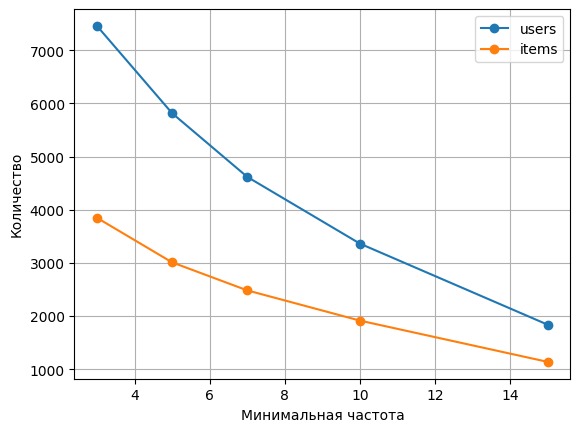

,users,items
threshold,,
3,7459,3849
5,5817,3011
7,4619,2484
10,3363,1915
15,1837,1138


In [28]:
# your code here
thresholds = [3, 5, 7, 10, 15]
filtered = {t: filter_dataframe(train_unique, ['user_id', 'item_id'], t) for t in thresholds}
frequency = pd.DataFrame([(t, x.user_id.nunique(), x.item_id.nunique()) for t, x in filtered.items()], columns=['threshold', 'users', 'items']).set_index('threshold')
frequency.plot(marker='o', xlabel='Минимальная частота', ylabel='Количество', grid=True)
plt.show()
frequency

**Задание №7. EASE**

Реализуйте EASE, постройте рекомендации для юзеров. Сравните все имплементированные ранее метрики качества с `TopPopular` для некоторого набора k. 

Реализацию можно взять из семинара. Можно реализовать по статье https://arxiv.org/pdf/1905.03375.pdf. Можно взять и адаптировать из RecBole https://github.com/RUCAIBox/RecBole.

In [29]:
%%time
# Обучаем EASE на обучающей матрице.
def fit_ease(X, reg_weight=1000):
    # your code here
    gram = (X.T @ X).toarray().astype(np.float64)
    gram.flat[::len(gram)+1] += reg_weight
    precision = np.linalg.inv(gram)
    B = -precision / np.diag(precision)[None, :]
    np.fill_diagonal(B, 0)
    return B
w = fit_ease(matrix)

CPU times: total: 2.28 s
Wall time: 1.34 s


Далее, вам надо реализовать функцию получения предсказаний. У вас есть обученная матрица весов, которую можно использовать для получения предсказаний. Для этого нужно построить вектор интеракций пользователя и умножить его на матрицу весов.

In [30]:
def get_preds(x, item2id, id2item, weights=None, topn=100):
    #your code here
    weights = w if weights is None else weights
    indices = [item2id[item] for item, _ in x if item in item2id]
    scores = weights[indices].sum(axis=0) if indices else np.zeros(len(item2id))
    order = np.argsort(-scores, kind='stable')[:topn]
    decoded = [id2item[int(i)] for i in order]
    return decoded
joined['ease_preds'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item))
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,window_recs,ease_preds
0,382,"[(1112, 89), (565, 129), (10605, 131), (5411, ...","[(11047, 153)]","[7498, 14901, 1582, 10162, 9978, 15885, 5232, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[16166, 7571, 10605, 3182, 16270, 13018, 7582,..."
1,446,"[(13865, 105)]","[(12202, 160), (230, 160)]","[2782, 10494, 15572, 11310, 956, 12598, 8815, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 3734, 15297, 12995, 4880, 8636, ..."
2,515,"[(3734, 114), (9728, 114), (4457, 115), (13865...","[(512, 158), (6330, 158), (9811, 159), (14488,...","[4127, 3609, 1682, 4366, 565, 13655, 7250, 811...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 4151, 13865, 15297, 9728, 3734, 4880, ..."
3,545,"[(10440, 92), (5803, 92), (6106, 103), (6455, ...","[(6638, 158), (5693, 161)]","[2190, 9742, 16224, 2972, 752, 14685, 1240, 12...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 9728, 15297, 13865, 4151, 3734, 2657, ..."
4,587,"[(4151, 64), (1400, 64), (4880, 69), (5658, 70...","[(11118, 153), (6192, 154)]","[2591, 1821, 14271, 12628, 1819, 3761, 2433, 1...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 13865, 15297, 3734, 9728, 4880, 4151, ..."


In [31]:
# your code here
comparison = pd.DataFrame([{'k': k, 'model': name, **evaluate_recommender(joined, col, topn=k)}
                           for k in [1, 5, 10, 20, 50, 100]
                           for name, col in [('TopPopular', 'toppopular_recs'), ('EASE', 'ease_preds')]])
comparison

,k,model,map,mrr,hr
0,1,TopPopular,0.052500,0.052500,0.0525
1,1,EASE,0.086500,0.086500,0.0865
2,5,TopPopular,0.063494,0.113083,0.2223
3,5,EASE,0.073248,0.132432,0.2161
4,10,TopPopular,0.066869,0.120683,0.2768
5,10,EASE,0.077530,0.142612,0.2934
6,20,TopPopular,0.071490,0.126674,0.3593
7,20,EASE,0.082138,0.148640,0.3801
8,50,TopPopular,0.074938,0.130316,0.4707
9,50,EASE,0.086288,0.152672,0.5060


При K=10 EASE с регуляризацией 1000 дал MAP 0,0775, MRR 0,1426 и HR 0,2934, TopPopular — 0,0669, 0,1207 и 0,2768. Уже просмотренные объекты остаются кандидатами для обеих моделей. Пользователи выбраны из тех, кто встречается и в train, и в test.

**Задание №8. Тюнинг**

Переберите различные значения гиперпараметра коэффициента регуляризации у EASE и постройте графики, как в задании №6. Постарайтесь "затюнить" EASE как можно лучше. Возьмите разумное число гиперпараметров - хотя бы штук 20 по логарифмической сетке, либо используйте более хитрые алгоритмы оптимизации. 

C:\Users\Иван\AppData\Local\Temp\ipykernel_34396\2697585021.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  val_sequences = val_train.groupby('user_id').apply(lambda x: list(zip(x.item_id, x.last_watch_dt)))


C:\Users\Иван\AppData\Local\Temp\ipykernel_34396\2697585021.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  val_targets = val_test.groupby('user_id').apply(lambda x: list(zip(x.item_id, x.last_watch_dt)))


  0%|          | 0/25 [00:00<?, ?it/s]

  4%|▍         | 1/25 [00:00<00:22,  1.05it/s]

  8%|▊         | 2/25 [00:01<00:19,  1.18it/s]

...

 88%|████████▊ | 22/25 [00:18<00:02,  1.26it/s]

 92%|█████████▏| 23/25 [00:19<00:01,  1.24it/s]

 96%|█████████▌| 24/25 [00:20<00:00,  1.19it/s]

100%|██████████| 25/25 [00:21<00:00,  1.14it/s]

100%|██████████| 25/25 [00:21<00:00,  1.18it/s]

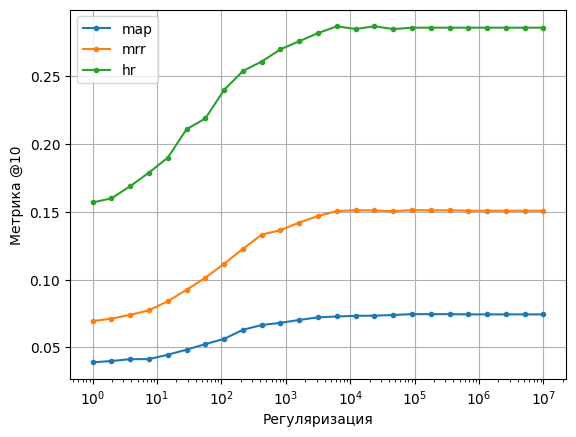

Лучшая регуляризация по validation MAP@10: 90851.75756516881


,map,mrr,hr
1.000000e+00,0.039022,0.069449,0.157
1.957342e+00,0.039962,0.071300,0.160
3.831187e+00,0.041363,0.074054,0.169
7.498942e+00,0.041371,0.077450,0.179
1.467799e+01,0.044611,0.084044,0.190
2.872985e+01,0.048340,0.092562,0.211
5.623413e+01,0.052451,0.101416,0.219
1.100694e+02,0.056313,0.111776,0.240
2.154435e+02,0.063032,0.122763,0.254
4.216965e+02,0.066539,0.133272,0.261


In [32]:
#your code here
# Валидация — неделя перед test, обучение параметра только на более ранних данных.
val_cut = 153 - 7
val_train = train_df[train_df.last_watch_dt < val_cut].drop_duplicates(['user_id', 'item_id'])
val_test = train_df[train_df.last_watch_dt >= val_cut]
val_filtered = filter_dataframe(val_train, ['user_id', 'item_id'], 5)
val_encoded = df_encode(val_filtered)
val_matrix = sps.csr_matrix((np.ones(len(val_encoded), dtype=np.float32), (val_encoded.user_id, val_encoded.item_id)), shape=(len(user2id), len(item2id)))
val_sequences = val_train.groupby('user_id').apply(lambda x: list(zip(x.item_id, x.last_watch_dt)))
val_targets = val_test.groupby('user_id').apply(lambda x: list(zip(x.item_id, x.last_watch_dt)))
val_users = np.intersect1d(val_sequences.index, val_targets.index)
rng = np.random.default_rng(777)
val_users = np.sort(rng.choice(val_users, size=min(1000, len(val_users)), replace=False))
val_joined = pd.DataFrame({'train_interactions': val_sequences.reindex(val_users), 'test_interactions': val_targets.reindex(val_users)})
# Спектральное разложение Gram вычисляется один раз для всех 25 значений.
G = (val_matrix.T @ val_matrix).toarray().astype(np.float64)
eigenvalues, eigenvectors = np.linalg.eigh(G)
regs = np.logspace(0, 7, 25)
tuning = []
for reg in tqdm(regs):
    P = (eigenvectors / (eigenvalues + reg)) @ eigenvectors.T
    weights = -P / np.diag(P)[None, :]
    np.fill_diagonal(weights, 0)
    val_joined['pred'] = val_joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, weights, 10))
    tuning.append(evaluate_recommender(val_joined, 'pred', topn=10))
tuning_table = pd.DataFrame(tuning, index=regs)
best_reg = float(tuning_table['map'].idxmax())
tuning_table.plot(logx=True, marker='.', xlabel='Регуляризация', ylabel='Метрика @10', grid=True)
plt.show()
print('Лучшая регуляризация по validation MAP@10:', best_reg)
tuning_table

8.1 Лучшее значение среди 25 проверенных — примерно 90 852: validation MAP@10 равен 0,07461.

8.2 MAP@10 вырос с 0,0390 при регуляризации 1 и вышел на плато около 0,0744–0,0746 при больших значениях. Максимумы MRR и HR приходятся на другие точки. Один спектральный расчёт для всей сетки сокращает число полных разложений, выбор основан на 1000 валидационных пользователях.

**Задание №9. EASE и topk**

В лекции №2 говорилось, что качество у EASE растет с ослаблением фильтра на число айтемов. В этом задании постройте кривые метрик качества MAP/MRR/HR в зависимости от topk (например, от 1 до 100 с некоторым шагом), где кривая параметризована минимальным требуемым значением встречаемости user/item (из задания №6). Опишите свои выводы.

Важно: в этом задании линии могут быть мало различимыми, поэтому ваша задача для каждой метрики найти нужный масштаб на каких-то конкретных topk, чтобы линии стали визуально отличимы. 

,threshold,k,map,mrr,hr
0,3,1,0.091700,0.091700,0.0917
1,3,2,0.081775,0.120150,0.1486
2,3,5,0.080830,0.144892,0.2377
3,3,10,0.083305,0.152205,0.2951
4,3,20,0.087604,0.158280,0.3789
5,3,30,0.089502,0.160304,0.4298
6,3,50,0.091437,0.162077,0.4983
7,3,75,0.092569,0.162986,0.5538
8,3,100,0.093301,0.163496,0.5980
9,5,1,0.091900,0.091900,0.0919


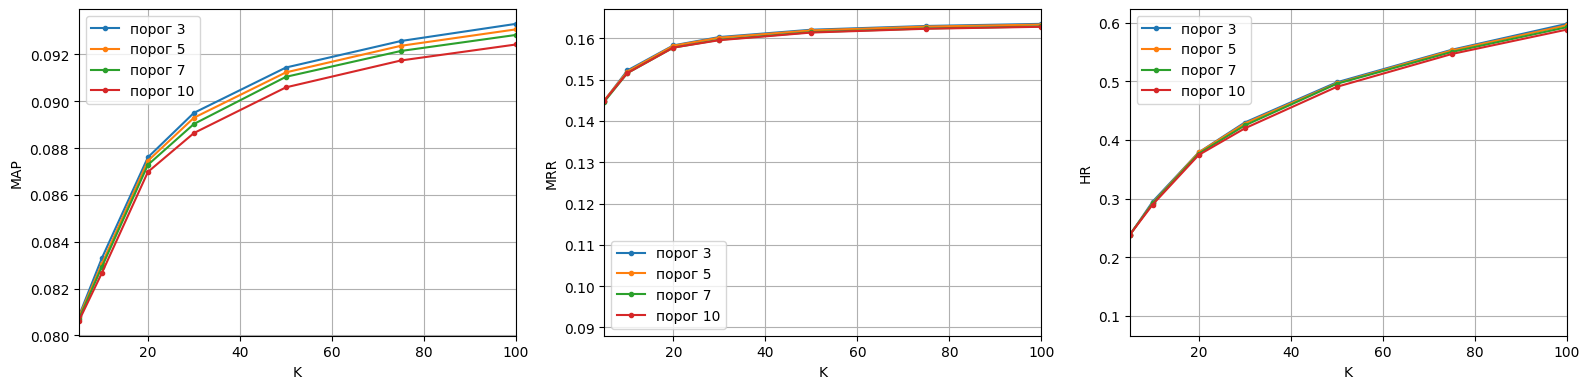

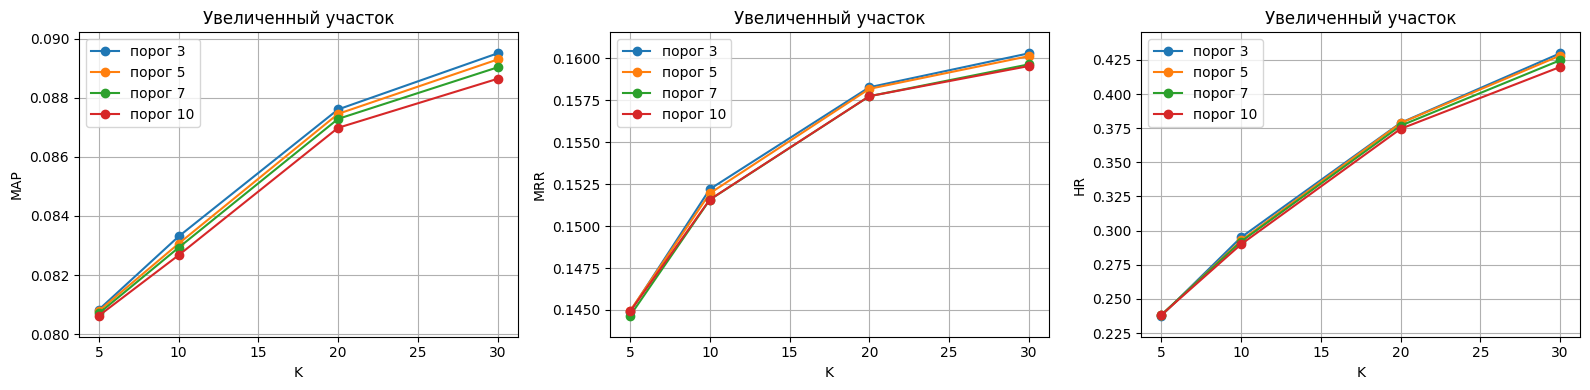

In [33]:
# your code here
curves = []
for threshold in [3, 5, 7, 10]:
    part = filtered[threshold]
    enc = df_encode(part)
    X = sps.csr_matrix((np.ones(len(enc), dtype=np.float32), (enc.user_id, enc.item_id)), shape=(len(user2id), len(item2id)))
    weights = fit_ease(X, best_reg)
    joined['threshold_preds'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, weights))
    for k in ks:
        curves.append({'threshold': threshold, 'k': k, **evaluate_recommender(joined, 'threshold_preds', topn=k)})
curve_table = pd.DataFrame(curves)
display(curve_table)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ['map', 'mrr', 'hr']):
    for threshold, group in curve_table.groupby('threshold'):
        ax.plot(group.k, group[metric], marker='.', label=f'порог {threshold}')
    ax.set(xlabel='K', ylabel=metric.upper(), xlim=(5, 100))
    ax.grid()
    ax.legend()
plt.tight_layout()
plt.show()
curve_table
# Увеличиваем участок K=5..30 и задаём масштаб по фактическому разбросу значений.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
zoom = curve_table[curve_table.k.between(5, 30)]
for ax, metric in zip(axes, ['map', 'mrr', 'hr']):
    for threshold, group in zoom.groupby('threshold'):
        ax.plot(group.k, group[metric], marker='o', label=f'порог {threshold}')
    lo, hi = zoom[metric].min(), zoom[metric].max()
    margin = max((hi-lo)*0.08, 1e-5)
    ax.set(xlabel='K', ylabel=metric.upper(), ylim=(lo-margin, hi+margin), title='Увеличенный участок')
    ax.grid()
    ax.legend()
plt.tight_layout()
plt.show()

При K=10 ослабление порога с 10 до 3 повысило MAP с 0,08267 до 0,08331, MRR с 0,15158 до 0,15221 и HR с 0,2900 до 0,2951. Различия малы и не сохраняют один порядок при всех K: например, при K=1 MAP для порога 5 чуть выше, чем для 3. Это в целом согласуется с ожиданием, что более слабый фильтр оставляет больше данных. Если история пользователя не содержит объектов обученного каталога, оценки одинаковы, а порядок задаётся идентификаторами.

**Задание №10. Интерпретируемые рекомендации**

Используйте выученную матрицу весов для item2item рекомендаций. Приведите 10 примеров топ-5 рекомендаций от EASE к сэмплируемым айтемам. Используйте названия фильмов вместо id при выводе рекомендаций. 

In [34]:
# your code here
# Восстанавливаем кодировки финальной модели после валидации.
encoded_train = df_encode(filtered_train)
w = fit_ease(matrix, best_reg)
joined['ease_tuned'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, w))
final_comparison = pd.DataFrame([{'k': k, 'model': name, **evaluate_recommender(joined, col, topn=k)} for k in [1, 5, 10, 20, 50, 100] for name, col in [('TopPopular', 'toppopular_recs'), ('EASE tuned', 'ease_tuned')]])
display(final_comparison)
titles = items.drop_duplicates('item_id').set_index('item_id').title
rng = np.random.default_rng(777)
examples = rng.choice(list(item2id), size=10, replace=False)
for item in examples:
    scores = w[item2id[item]].copy()
    scores[item2id[item]] = -np.inf
    recommended = [id2item[int(i)] for i in np.argsort(-scores)[:5]]
    print(f"{titles.get(item, str(item))}: " + ', '.join(str(titles.get(i, i)) for i in recommended))

,k,model,map,mrr,hr
0,1,TopPopular,0.052500,0.052500,0.0525
1,1,EASE tuned,0.091900,0.091900,0.0919
2,5,TopPopular,0.063494,0.113083,0.2223
3,5,EASE tuned,0.080785,0.144942,0.2380
4,10,TopPopular,0.066869,0.120683,0.2768
5,10,EASE tuned,0.083062,0.151955,0.2928
6,20,TopPopular,0.071490,0.126674,0.3593
7,20,EASE tuned,0.087454,0.158186,0.3787
8,50,TopPopular,0.074938,0.130316,0.4707
9,50,EASE tuned,0.091230,0.161914,0.4966


Воскресение Христа: Гнев человеческий, Девятаев, Ford против Ferrari, Альфа, Девятаев
Больше, чем друзья: Клиника счастья, Хрустальный, Девятаев, Фемида видит, Прабабушка легкого поведения
Форма воды: Гнев человеческий, Хрустальный, Девятаев, Клиника счастья, Маша
Ханна. Совершенное оружие: Гнев человеческий, Хрустальный, Девятаев, Прабабушка легкого поведения, Секреты семейной жизни
Донбасс. Окраина: Девятаев, Гнев человеческий, Хрустальный, Афера, Восемь сотен
Невероятные приключения Факира: Гнев человеческий, Хрустальный, Дуров, Афера, Прабабушка легкого поведения
Дневники шаловливых подростков: Девичий рай, Фантазии пар, Большие любители ног, Двойное удовольствие, Коробка с игрушками Пентхаус
Звёздные войны: Империя наносит ответный удар: Звёздные войны: Эпизод 4 — Новая надежда, Звёздные войны: Возвращение Джедая, Звёздные войны: Скрытая угроза, Звёздные войны: Атака клонов, Звёздные войны: Пробуждение силы
Осторожно, дети!: Секреты семейной жизни, Прабабушка легкого поведения, Аф

Для «Звёздные войны: Империя наносит ответный удар» модель предлагает другие части той же серии — это убедительный пример. Для «Форма воды» в списке преобладают общепопулярные «Гнев человеческий», «Хрустальный» и «Девятаев», тематическая связь по названиям неочевидна. EASE учитывает совместные просмотры и может отражать популярность и особенности выборки, а не смысловое сходство. Одинаковые названия также могут относиться к разным ID в каталоге.